# 02 · Busca semântica: recall@1/@3 e limiar de "não consta"
Embeddings `intfloat/multilingual-e5-base` (prefixos `query:`/`passage:`, vetores normalizados, similaridade = cosseno).

**Duas versões da busca.** v1 embute só o texto do trecho. Na 1ª execução da v1 o recall@3 foi 0,68 e 6 de 9 falhas eram confusão entre os manuais SCI-100/200/300. A v2 coloca o nome do documento no início do trecho antes de gerar o embedding (cabeçalho contextual, `config.DOC_ALIAS`; o texto do trecho e as citações não mudam). A v2 foi adotada **depois** de ver as falhas da v1 (inclusive no teste); registramos as duas para transparência.

- **recall@k**: fração das perguntas respondíveis em que algum dos top-k trechos vem do documento esperado **e** cobre uma das páginas esperadas.
- **recall_fatos@3**: os 3 trechos juntos contêm todos os fatos-chave (justo com manuais que repetem o mesmo conteúdo). A v1 indexa só o texto do trecho; a v2 acrescenta o nome do documento ao embedding (os manuais SCI-100/200/300 eram confundidos entre si). Ambas ficam registradas no relatório.
- **Limiar**: abaixo dele o sistema responde "não consta" **sem chamar o LLM**. É calibrado no split `dev` (máx. F1 entre "respondível" e "não consta") e **confirmado no split `teste`** (que não participou da calibração).

In [1]:
# --- Ambiente: funciona no Colab (via VSCode ou navegador) e localmente ---------------
import os, sys, subprocess
from pathlib import Path

REPO_URL = ""   # opcional: URL do repositório GitHub, se o projeto ainda não estiver na máquina do Colab

try:
    os.getcwd()
except FileNotFoundError:      # a pasta atual do kernel foi apagada/recriada: volta para um lugar válido
    os.chdir("/content" if Path("/content").exists() else str(Path.home()))

def achar_raiz():
    cwd = Path.cwd()
    cands = [cwd, *cwd.parents, Path("/content/GS2-GENIA"), Path("/content/drive/MyDrive/GS2-GENIA"),
             Path("/content/drive/MyDrive/GEN-IA/GS2-GENIA"), Path("/content/drive/MyDrive/GEN-IA")]
    for c in cands:
        if (c / "src" / "config.py").exists():
            return c
    for base in (Path("/content"), Path("/content/drive/MyDrive")):   # busca 1-2 níveis abaixo
        if base.exists():
            for f in list(base.glob("*/src/config.py")) + list(base.glob("*/*/src/config.py")):
                return f.parent.parent
    return None

ROOT = achar_raiz()
if ROOT is None and REPO_URL:
    subprocess.run(["git", "clone", REPO_URL, "/content/GS2-GENIA"], check=True)
    ROOT = Path("/content/GS2-GENIA")
assert ROOT is not None, "Não achei src/config.py: abra o notebook dentro da pasta GS2-GENIA ou preencha REPO_URL."
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
print("ROOT =", ROOT)

ROOT = /content/drive/MyDrive/GS2-GENIA


In [2]:
%pip install -q -r requirements.txt

In [3]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src import config
from src.ingest import load_chunks
from src.evaluate import load_testset
from src.retrieval import (Retriever, evaluate_recall, evaluate_recall_fatos, top1_scores,
                           calibrate_threshold, metrics_at, save_threshold)

chunks = load_chunks()
retriever_v1 = Retriever(chunks, header=False)   # v1: só o texto do trecho
retriever = Retriever(chunks, header=True)      # v2: nome do documento no embedding
dev, teste = load_testset(split="dev"), load_testset(split="teste")
print(len(chunks), "trechos |", len(dev), "dev |", len(teste), "teste")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Batches:   0%|          | 0/41 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Batches:   0%|          | 0/41 [00:00<?, ?it/s]

1312 trechos | 20 dev | 20 teste


In [4]:
res = {}
for ver, rt in [("v1 sem cabeçalho", retriever_v1), ("v2 com cabeçalho", retriever)]:
    for nome, its in [("dev", dev), ("teste", teste), ("todos", dev + teste)]:
        r = evaluate_recall(rt, its)
        res[(ver, nome)] = {"n": r.n, "recall@1": round(r.recall_at_1, 3), "recall@3": round(r.recall_at_3, 3),
                            "recall_fatos@3": round(evaluate_recall_fatos(rt, its), 3)}
recall_df = pd.DataFrame(res).T
display(recall_df)
r_all = evaluate_recall(retriever, dev + teste)
print("Perguntas sem acerto no top-3 (v2, para a seção de erros):")
display(pd.DataFrame(r_all.misses))
(ROOT / "avaliacao").mkdir(exist_ok=True)
recall_df.to_csv(ROOT / "avaliacao" / "recall.csv")

n  recall@1  recall@3  recall_fatos@3
v1 sem cabeçalho dev    14.0     0.429     0.714           0.714
                 teste  14.0     0.571     0.643           0.500
                 todos  28.0     0.500     0.679           0.607
v2 com cabeçalho dev    14.0     0.500     0.714           0.786
                 teste  14.0     0.643     0.786           0.714
                 todos  28.0     0.571     0.750           0.750

Perguntas sem acerto no top-3 (v2, para a seção de erros):


,id,pergunta,esperado,top1,score_top1
0,Q06,Qual o papel dos pesquisadores no manejo integ...,DOC002,DOC002-p005-c010,0.888517
1,Q17,"Segundo o SCI-300, qual é a função do Plano de...",DOC008,DOC008-p176-c349,0.915904
2,Q22,"Segundo o SCI-200, quando o Plano de Ação do I...",DOC007,DOC007-p119-c271,0.901001
3,Q25,"Segundo o SCI-100, qual é a diferença entre co...",DOC006,DOC007-p101-c206,0.895905
4,Q05,Segundo o Guia Prático de Manejo Integrado do ...,DOC002,DOC002-p005-c010,0.897477
5,Q10,O que é o Sisfogo?,DOC003,DOC007-p117-c261,0.838031
6,Q23,"Segundo o SCI-100, o que é o Sistema de Comand...",DOC006,DOC006-p082-c162,0.925565


## Calibração do limiar (apenas `dev`) e confirmação (`teste`)

Limiar escolhido (dev): 0.8359  | F1=0.933 precisão=0.875 recall=1.000
No TESTE com o mesmo limiar: {'threshold': 0.836, 'precision': 0.778, 'recall': 1.0, 'f1': 0.875, 'tp': 14, 'fp': 4, 'fn': 0, 'tn': 2}


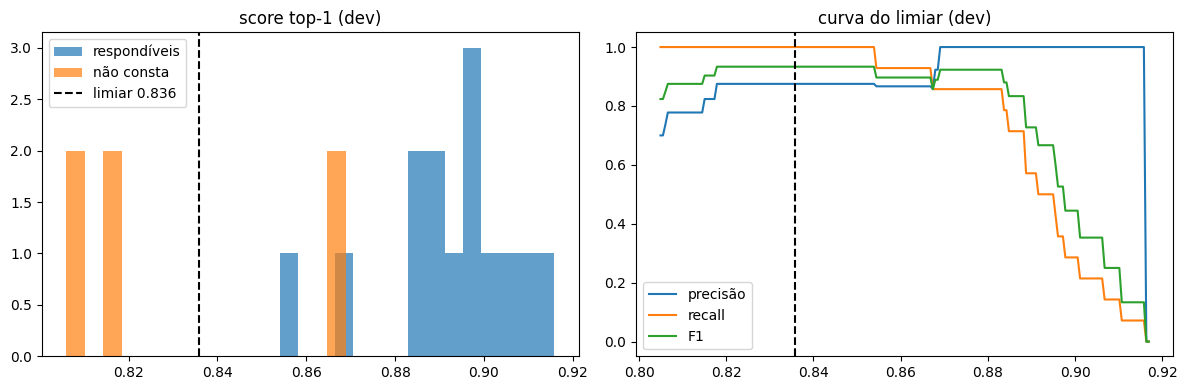

gravado em results/threshold.json


In [5]:
s_dev = top1_scores(retriever, dev)
info = calibrate_threshold(s_dev)
th = info["threshold"]
print(f"Limiar escolhido (dev): {th:.4f}  | F1={info['f1']:.3f} precisão={info['precision']:.3f} recall={info['recall']:.3f}")

s_teste = top1_scores(retriever, teste)
conf = metrics_at(s_teste, th)
print("No TESTE com o mesmo limiar:", {k: (round(v, 3) if isinstance(v, float) else v) for k, v in conf.items()})

curve = pd.DataFrame(info["curve"])
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
resp = [s for s, rec in s_dev if not rec]; nao = [s for s, rec in s_dev if rec]
ax[0].hist(resp, bins=15, alpha=.7, label="respondíveis"); ax[0].hist(nao, bins=15, alpha=.7, label="não consta")
ax[0].axvline(th, color="k", ls="--", label=f"limiar {th:.3f}"); ax[0].set_title("score top-1 (dev)"); ax[0].legend()
ax[1].plot(curve.threshold, curve.precision, label="precisão"); ax[1].plot(curve.threshold, curve.recall, label="recall")
ax[1].plot(curve.threshold, curve.f1, label="F1"); ax[1].axvline(th, color="k", ls="--"); ax[1].legend(); ax[1].set_title("curva do limiar (dev)")
plt.tight_layout(); plt.savefig(ROOT / "avaliacao" / "limiar.png", dpi=120); plt.show()

info["confirmacao_teste"] = {k: v for k, v in conf.items()}
info["recall_teste"] = recall_df.loc[("v2 com cabeçalho", "teste")].to_dict()
save_threshold(info)
print("gravado em results/threshold.json")

### Justificativa do limiar (preencha com os números acima)
- O limiar fica no centro do patamar de F1 máximo no `dev`, para não colar na borda de um empate.
- Trade-off: **limiar alto** → mais recusas indevidas (perde respostas certas); **limiar baixo** → deixa passar perguntas fora da base para o LLM (risco de alucinação). Para um sistema de defesa civil preferimos errar para o lado de recusar, mas o limiar não pode sacrificar demais o recall.
- Se no `teste` a precisão/recall caírem muito em relação ao `dev`, o limiar está ajustado demais a 20 perguntas: registrar isso na conclusão (amostra pequena).